# Drzewa decyzyjne – case study: choroby serca (Heart)

**Plan notatnika:**
1. Dane
2. Podział na zbiór treningowy i testowy
3. Baseline
4. Drzewo decyzyjne
5. Ocena modelu
6. Interpretacja drzewa
7. Głębokość drzewa a przeuczenie
8. Podsumowanie

Zbiór `heart.csv` zawiera wyniki badań medycznych 303 pacjentów (źródło: [Kaggle](https://www.kaggle.com/datasets/arezaei81/heartcsv)). Zadanie: klasyfikacja binarna – na podstawie wyników badań przewidzieć wartość zmiennej celu `target` (0 lub 1).

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

## 1. Dane

In [5]:
df = pd.read_csv('heart.csv')
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


| Kolumna | Opis |
|---|---|
| `age` | wiek (lata) |
| `sex` | płeć (1 – mężczyzna, 0 – kobieta) |
| `cp` | rodzaj bólu w klatce piersiowej (4 wartości: 0–3) |
| `trestbps` | spoczynkowe ciśnienie krwi (mm Hg) |
| `chol` | cholesterol (mg/dl) |
| `fbs` | cukier we krwi na czczo > 120 mg/dl (1 – tak, 0 – nie) |
| `restecg` | wynik spoczynkowego EKG (0–2) |
| `thalach` | maksymalne tętno osiągnięte w teście wysiłkowym |
| `exang` | ból w klatce piersiowej wywołany wysiłkiem (1 – tak, 0 – nie) |
| `oldpeak` | obniżenie odcinka ST w teście wysiłkowym względem spoczynku |
| `slope` | nachylenie odcinka ST w szczycie wysiłku (0–2) |
| `ca` | liczba głównych naczyń zabarwionych w badaniu fluoroskopowym (0–4) |
| `thal` | wynik badania talasemii (kody 0–3) |
| `target` | **zmienna celu**: diagnoza choroby serca, zmienna binarna (0 lub 1); 1 – choroba serca, 0 – brak choroby | |


In [6]:
print('Kształt:', df.shape)
print('Braki danych:', df.isna().sum().sum())
print('Zduplikowane wiersze:', df.duplicated().sum())

Kształt: (303, 14)
Braki danych: 0
Zduplikowane wiersze: 1


In [7]:
# duplikaty usuwamy, żeby ta sama obserwacja nie trafiła jednocześnie do zbioru treningowego i testowego
df = df.drop_duplicates().reset_index(drop=True)
print('Kształt po usunięciu duplikatów:', df.shape)

Kształt po usunięciu duplikatów: (302, 14)


In [8]:
df.describe().round(2)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00,302.00
mean,54.42,0.68,0.96,131.60,246.50,0.15,0.53,149.57,0.33,1.04,1.40,0.72,2.31,0.54
std,9.05,0.47,1.03,17.56,51.75,0.36,0.53,22.90,0.47,1.16,0.62,1.01,0.61,0.50
min,29.00,0.00,0.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,48.00,0.00,0.00,120.00,211.00,0.00,0.00,133.25,0.00,0.00,1.00,0.00,2.00,0.00
50%,55.50,1.00,1.00,130.00,240.50,0.00,1.00,152.50,0.00,0.80,1.00,0.00,2.00,1.00
75%,61.00,1.00,2.00,140.00,274.75,0.00,1.00,166.00,1.00,1.60,2.00,1.00,3.00,1.00
max,77.00,1.00,3.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,2.00,4.00,3.00,1.00


In [9]:
df['target'].value_counts()

target
1    164
0    138
Name: count, dtype: int64

Klasy są dość zbalansowane (żadna nie dominuje), więc zwykła trafność (`accuracy`) jest tu sensowną metryką.

## 2. Podział na zbiór treningowy i testowy

In [10]:
X = df.drop(columns='target')
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print('Zbiór treningowy:', X_train.shape, '  testowy:', X_test.shape)

Zbiór treningowy: (226, 13)   testowy: (76, 13)


## 3. Baseline

Punkt odniesienia: model, który zawsze wskazuje klasę najczęstszą.

In [11]:
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
print(f'Accuracy baseline: {baseline.score(X_test, y_test):.3f}')

Accuracy baseline: 0.539


## 4. Drzewo decyzyjne

Ustawiamy `max_depth=3`, żeby drzewo było małe i czytelne. Cech nie skalujemy – drzewa tego nie wymagają.

In [12]:
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f'Accuracy trening: {model.score(X_train, y_train):.3f}')
print(f'Accuracy test:    {accuracy_score(y_test, y_pred):.3f}')

Accuracy trening: 0.854
Accuracy test:    0.750


In [13]:
# porównanie kilku pierwszych predykcji z prawdziwymi wartościami
pd.DataFrame({'prawdziwa': y_test.to_numpy(), 'przewidziana': y_pred}).head(10).T

,0,1,2,3,4,5,6,7,8,9
prawdziwa,0,0,0,0,0,0,0,1,1,0
przewidziana,0,0,0,0,1,0,0,0,1,1


## 5. Ocena modelu

Sama trafność nie mówi, jakie błędy popełnia model. Macierz pomyłek i raport klasyfikacji (metryki omówiliśmy w rozdziale 3.2) pokazują to dokładniej.

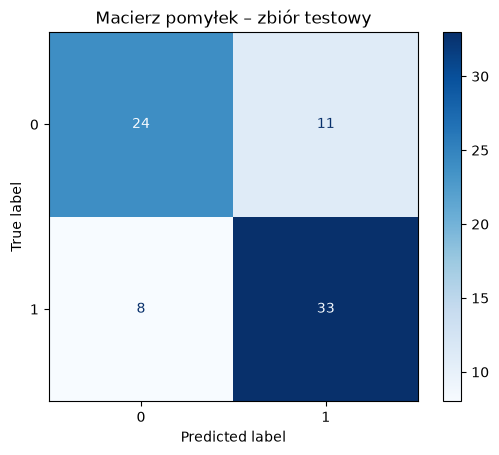

              precision    recall  f1-score   support

           0       0.75      0.69      0.72        35
           1       0.75      0.80      0.78        41

    accuracy                           0.75        76
   macro avg       0.75      0.75      0.75        76
weighted avg       0.75      0.75      0.75        76



In [14]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap='Blues')
plt.title('Macierz pomyłek – zbiór testowy')
plt.show()

print(classification_report(y_test, y_pred))

## 6. Interpretacja drzewa

Największa zaleta drzewa to możliwość zobaczenia, **jakie reguły** zastosował model.

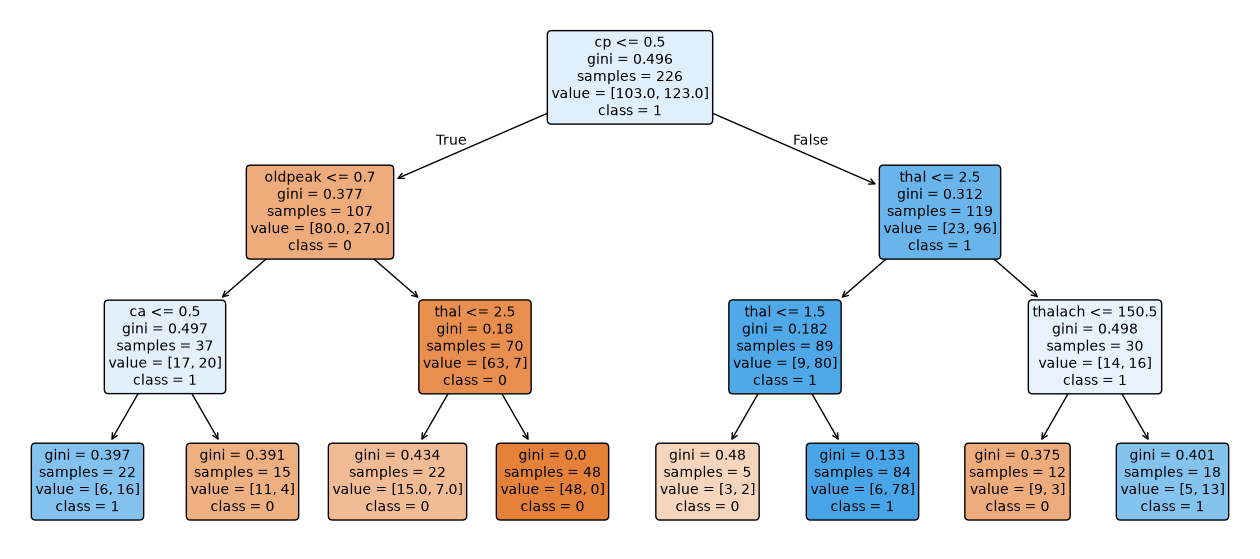

In [15]:
plt.figure(figsize=(16, 7))
plot_tree(model, feature_names=list(X.columns), class_names=['0', '1'],
          filled=True, rounded=True, fontsize=10)
plt.show()

In [16]:
print(export_text(model, feature_names=list(X.columns)))

|--- cp <= 0.50
|   |--- oldpeak <= 0.70
|   |   |--- ca <= 0.50
|   |   |   |--- class: 1
|   |   |--- ca >  0.50
|   |   |   |--- class: 0
|   |--- oldpeak >  0.70
|   |   |--- thal <= 2.50
|   |   |   |--- class: 0
|   |   |--- thal >  2.50
|   |   |   |--- class: 0
|--- cp >  0.50
|   |--- thal <= 2.50
|   |   |--- thal <= 1.50
|   |   |   |--- class: 0
|   |   |--- thal >  1.50
|   |   |   |--- class: 1
|   |--- thal >  2.50
|   |   |--- thalach <= 150.50
|   |   |   |--- class: 0
|   |   |--- thalach >  150.50
|   |   |   |--- class: 1



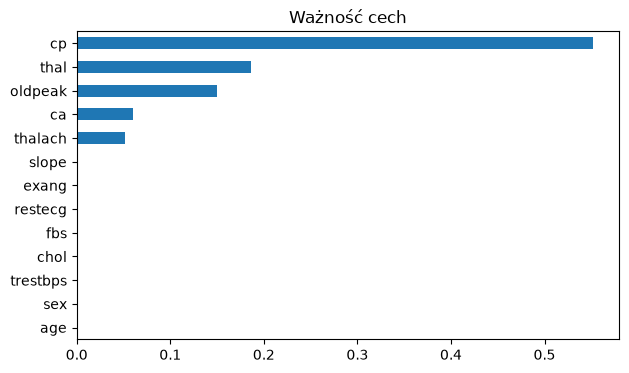

In [17]:
waznosc = pd.Series(model.feature_importances_, index=X.columns).sort_values()
waznosc.plot.barh(figsize=(7, 4), title='Ważność cech')
plt.show()

Jak czytać drzewo:
- warunek w węźle (np. `cp <= 0.5`): spełniony → idziemy w **lewo**, niespełniony → w **prawo**,
- `value = [a, b]` to liczba obserwacji klasy 0 i klasy 1 w węźle,
- im bardziej jednolity kolor i niższy `gini`, tym „czystszy” węzeł.

Cechy użyte w korzeniu i najbliżej niego mają największą ważność. Warto zwrócić uwagę, że ranking ważności zależy od konkretnego drzewa i zbioru treningowego, więc jest to wskazówka, a nie dowód zależności przyczynowej.

## 7. Głębokość drzewa a przeuczenie

Sprawdźmy, co się stanie, gdy nie ograniczymy głębokości.

In [18]:
wyniki = []
for glebokosc in [1, 2, 3, 4, 5, 8, None]:
    m = DecisionTreeClassifier(max_depth=glebokosc, random_state=42).fit(X_train, y_train)
    wyniki.append({'max_depth': 'bez limitu' if glebokosc is None else glebokosc,
                   'głębokość drzewa': m.get_depth(),
                   'liczba liści': m.get_n_leaves(),
                   'accuracy trening': round(m.score(X_train, y_train), 3),
                   'accuracy test': round(m.score(X_test, y_test), 3)})
pd.DataFrame(wyniki)

,max_depth,głębokość drzewa,liczba liści,accuracy trening,accuracy test
0,1,1,2,0.779,0.697
1,2,2,4,0.792,0.697
2,3,3,8,0.854,0.750
3,4,4,15,0.903,0.816
4,5,5,22,0.929,0.789
5,8,8,40,0.991,0.763
6,bez limitu,9,42,1.000,0.724


Drzewo bez limitu osiąga 100% na zbiorze treningowym (zapamiętuje dane), a na testowym wypada gorzej niż drzewa o głębokości 3–5 – to przeuczenie. Wynik testowy z jednego podziału danych jest też dość **niestabilny** (zbiór testowy ma tylko kilkadziesiąt obserwacji), dlatego do rzetelnego doboru parametrów używamy walidacji krzyżowej (rozdział 4.4).

## 8. Podsumowanie

1. Porównaliśmy drzewo z baseline'em i obejrzeliśmy jego reguły.
2. Płytkie drzewo daje czytelne reguły i przyzwoity wynik, a głębokie – zapamiętuje dane treningowe.
3. Przed pracą z danymi należy sprawdzić **znaczenie etykiet** i usunąć duplikaty.
4. Mały zbiór testowy daje niepewny wynik – stabilniejszą ocenę da walidacja krzyżowa.